# Predicting inadequate menstrual hygiene management (MHM) among Ethiopian women: revised, leakage-safe analysis
**Discover Artificial Intelligence – major revision.** Run the cells top to bottom in Google Colab.

What this notebook does differently from the first submission (each point answers an editor/reviewer comment):
1. Audits the file structure (one row per **birth** vs one row per **woman**) and builds a participant flow.
2. Recodes DHS special codes (e.g. `v115` 996 = "on premises", 997/998 = special; 7/97 = "not a de jure resident") to missing/valid values.
3. Uses **one row per woman**, **cluster-aware (PSU-grouped) train/test splitting**, and fits imputation, encoding, scaling and mutual-information feature selection **inside the training folds only** (scikit-learn Pipeline).
4. One-hot encodes nominal variables (no `LabelEncoder`); ordinal codes only where the order is defensible.
5. Declares the **positive class = inadequate MHM (1)** and recomputes every metric/confusion matrix directly from test-set predictions, with an arithmetic consistency check.
6. Reports ROC-AUC, PR-AUC, balanced accuracy, sensitivity, specificity, PPV, NPV, F1, Brier score, calibration slope/intercept, with cluster-bootstrap 95% CIs, repeated-CV mean ± SD, and a paired bootstrap comparison of the top models.
7. Compares class weighting (primary), SMOTEENN and random under-sampling; weighted vs unweighted fits; row-level vs woman-level vs cluster-aware splits (leakage demonstration).
8. Produces publication-quality figures (300 dpi PNG + vector PDF), SHAP beeswarm / dependence plots, and CSV tables for the manuscript.

In [20]:
# --- 0. Install / import ---------------------------------------------------
import sys, os, subprocess, importlib, importlib.util
def _pip(pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + pkgs, check=False)
_missing = [p for p, m in [("imbalanced-learn", "imblearn"), ("shap", "shap"), ("xgboost", "xgboost"),
                          ("lightgbm", "lightgbm"), ("statsmodels", "statsmodels")]
            if importlib.util.find_spec(m) is None]
if _missing and os.environ.get("MHM_NO_PIP") != "1":
    _pip(_missing)

import os, json, math, time, warnings, random
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, learning_curve, cross_val_predict, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss,
                             roc_curve, precision_recall_curve)

def _try(name):
    try:
        return importlib.import_module(name)
    except Exception:
        return None
xgb, lgb, shap, sm = _try("xgboost"), _try("lightgbm"), _try("shap"), _try("statsmodels.api")
imb = _try("imblearn.combine"); imb_under = _try("imblearn.under_sampling")
print({k: (v is not None) for k, v in dict(xgboost=xgb, lightgbm=lgb, shap=shap, statsmodels=sm, imblearn=imb).items()})

{'xgboost': True, 'lightgbm': True, 'shap': True, 'statsmodels': True, 'imblearn': True}


In [21]:
# --- 1. Configuration (EDIT THIS CELL) ---------------------------------------
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False

DATA_PATH = "/content/drive/MyDrive/DHIS/data_3.csv"      # <- path to the EDHS csv on your Drive
OUT_DIR   = "/content/drive/MyDrive/MHM_revision_outputs" # <- all tables/figures are written here
if not IN_COLAB:                                          # local testing fallback
    DATA_PATH = os.environ.get("MHM_DATA", DATA_PATH); OUT_DIR = os.environ.get("MHM_OUT", "./outputs")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(f"{OUT_DIR}/figures", exist_ok=True); os.makedirs(f"{OUT_DIR}/tables", exist_ok=True)

# ---- OUTCOME DEFINITION (your v247 definition, with ONE correction) ---------------------------
# Safe materials  : v247a-d  (reusable pad, disposable pad, tampon, menstrual cup)
# Unsafe materials: v247e, v247f, v247g, v247h, v247y
# Inadequate MHM (1) = any unsafe material OR no safe material; adequate (0) = safe material(s) only.
# CORRECTION: women with NO answer to any v247 item (module not asked) are now MISSING and excluded.
# In the original code, NaN != 1 evaluated to True, so those women were silently coded as inadequate.
OUTCOME_COL  = None
SAFE_COLS    = ["v247a", "v247b", "v247c", "v247d"]
UNSAFE_COLS  = ["v247e", "v247f", "v247g", "v247h", "v247y"]
MHM_FILE     = None            # only needed if the v247 columns are in a separate file keyed by caseid
SYNTHETIC_TEST = os.environ.get("MHM_SYNTHETIC", "0") == "1"   # code smoke-test only; NEVER use for results

DICT_PATH = "/content/drive/MyDrive/ETGR8AFL.DO"   # <- the EDHS data dictionary (.DO) you uploaded; used for variable and category NAMES
SEED = 42
if not IN_COLAB:
    DICT_PATH = os.environ.get("MHM_DICT", DICT_PATH)
FAST_MODE = True               # True: ~15-30 min on Colab; False: full grids / 1,000 bootstraps (hours)
N_BOOT   = 200 if FAST_MODE else 1000
N_ITER   = 5   if FAST_MODE else 20
CV_FOLDS = 3   if FAST_MODE else 5
REPEATS  = 2   if FAST_MODE else 5
K_FEATURES = 15
TEST_FRAC  = 0.20
if os.environ.get("MHM_SMOKE") == "1":      # local smoke test only
    N_BOOT, N_ITER, REPEATS = 30, 2, 1
random.seed(SEED); np.random.seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# --- 2. Load, audit structure, participant flow ------------------------------
raw = pd.read_csv(DATA_PATH, low_memory=False)
audit = {
    "rows_in_file": int(len(raw)),
    "unique_women_caseid": int(raw["caseid"].nunique()),
    "mean_rows_per_woman": round(len(raw) / raw["caseid"].nunique(), 2),
    "unique_PSU_v021": int(raw["v021"].nunique()),
    "unique_strata_v022": int(raw["v022"].nunique()),
    "survey_code_v000": sorted(raw["v000"].astype(str).unique().tolist()),
    "interview_years_v007": raw["v007"].value_counts().to_dict(),
}
print(json.dumps(audit, indent=2, default=str))
# Are the woman-level variables constant within woman? (they should be if each row is a birth/pregnancy record)
wl = ["v012", "v106", "v190", "v024", "v113", "v115", "v161", "v127", "v155", "v201", "v218"]
const_check = {c: int((raw.groupby("caseid")[c].nunique() > 1).sum()) for c in wl if c in raw}
print("women with >1 distinct value (0 = woman-level):", const_check)

# Collapse to ONE ROW PER WOMAN (unit of the outcome and of survey weights)
raw = raw.sort_values(["caseid"] + (["pidx"] if "pidx" in raw else [])).reset_index(drop=True)
birth_level = raw.copy()
women = raw.drop_duplicates("caseid").reset_index(drop=True)
print(f"Birth-level rows: {len(raw):,} -> woman-level rows: {len(women):,}")

{
  "rows_in_file": 55620,
  "unique_women_caseid": 14006,
  "mean_rows_per_woman": 3.97,
  "unique_PSU_v021": 797,
  "unique_strata_v022": 27,
  "survey_code_v000": [
    "ET8"
  ],
  "interview_years_v007": {
    "2024": 49732,
    "2025": 5888
  }
}
women with >1 distinct value (0 = woman-level): {'v012': 0, 'v106': 0, 'v190': 0, 'v024': 0, 'v113': 0, 'v115': 0, 'v161': 0, 'v127': 0, 'v155': 0, 'v201': 0, 'v218': 0}
Birth-level rows: 55,620 -> woman-level rows: 14,006


In [23]:
# --- 3. Outcome: inadequate MHM = 1 (POSITIVE CLASS), adequate MHM = 0 -------
def build_outcome(df):
    if MHM_FILE:
        extra = pd.read_csv(MHM_FILE, low_memory=False)
        df = df.merge(extra.drop_duplicates("caseid"), on="caseid", how="left", suffixes=("", "_mhm"))
    if OUTCOME_COL and OUTCOME_COL in df:
        return df[OUTCOME_COL].astype("float")
    if SAFE_COLS or UNSAFE_COLS:
        safe = df[SAFE_COLS].fillna(0).eq(1).any(axis=1) if SAFE_COLS else pd.Series(False, index=df.index)
        unsafe = df[UNSAFE_COLS].fillna(0).eq(1).any(axis=1) if UNSAFE_COLS else pd.Series(False, index=df.index)
        valid = df[SAFE_COLS + UNSAFE_COLS].notna().any(axis=1)
        y = (unsafe | ~safe).astype(float)          # any unsafe material OR no safe material -> inadequate
        return y.where(valid)
    return None

y_all = build_outcome(women)
if y_all is None and SYNTHETIC_TEST:
    rng = np.random.default_rng(SEED)
    z = -0.9 * (women["v190"] - 3) - 0.5 * (women["v106"] - 1) + rng.normal(0, 1.5, len(women)) + 1.3
    y_all = (z > 0).astype(float)
    print("!!! SYNTHETIC OUTCOME – SMOKE TEST ONLY !!!")
if y_all is None:
    raise RuntimeError("No outcome available. Check SAFE_COLS / UNSAFE_COLS (v247*) in the configuration cell.")
women["inadequate_mhm"] = y_all
n_valid = int(women["inadequate_mhm"].notna().sum())
print(f"Women with valid outcome: {n_valid:,}; prevalence of inadequate MHM (unweighted): {women['inadequate_mhm'].mean():.4f}")
n_na = int(women["inadequate_mhm"].isna().sum())
print(f"Women with NO v247 answer (module not asked) -> excluded, not coded inadequate: {n_na:,}")
_bug = (birth_level[UNSAFE_COLS].eq(1).any(axis=1) | ~birth_level[SAFE_COLS].eq(1).any(axis=1)).astype(int)   # what the old code did
print(f"Old coding at birth level: {int(_bug.sum()):,}/{len(_bug):,} = {_bug.mean():.4f} 'inadequate' (includes {int(((_bug==1) & ~birth_level[SAFE_COLS+UNSAFE_COLS].notna().any(axis=1)).sum()):,} records with no v247 answer)")

Women with valid outcome: 9,915; prevalence of inadequate MHM (unweighted): 0.5898
Women with NO v247 answer (module not asked) -> excluded, not coded inadequate: 4,091
Old coding at birth level: 44,340/55,620 = 0.7972 'inadequate' (includes 18,149 records with no v247 answer)


In [24]:
# --- 4. Recode DHS special codes; build the variable dictionary (33 candidate predictors) -------
SPECIAL = {  # column: {special category stored as a number: replacement}  (nan = missing)
    "v133": {97: np.nan},                               # Education in single years: "Inconsistent"
    "v115": {996: 0, 997: np.nan, 998: np.nan},       # time to water: 996 = on premises (0 min); 997/998 = not de jure / don't know
    "v113": {97: np.nan, 99: np.nan}, "v116": {97: np.nan, 99: np.nan}, "v161": {97: np.nan, 99: np.nan},
    "v127": {97: np.nan, 99: np.nan}, "v128": {97: np.nan, 99: np.nan}, "v129": {97: np.nan, 99: np.nan},
    "v119": {7: np.nan, 9: np.nan}, "v120": {7: np.nan, 9: np.nan}, "v121": {7: np.nan, 9: np.nan}, "v122": {7: np.nan, 9: np.nan},
    "v123": {7: np.nan, 9: np.nan}, "v124": {7: np.nan, 9: np.nan}, "v125": {7: np.nan, 9: np.nan}, "v160": {7: np.nan, 9: np.nan},
}
# v160 (toilet shared with other households) is only asked when a toilet exists -> structurally missing = "no facility to share" (0)
if "v160" in women:
    n_struct = int(women["v160"].isna().sum()); women["v160"] = women["v160"].fillna(0)
    print(f"v160: {n_struct} structurally missing (no toilet facility) coded 0 = not shared")
recode_log = []
for col, mp in SPECIAL.items():
    if col in women:
        for code, new in mp.items():
            n = int((women[col] == code).sum())
            if n:
                recode_log.append({"variable": col, "special_code": code, "n_women": n, "recoded_to": "missing" if pd.isna(new) else new})
        women[col] = women[col].replace(mp)
recode_log = pd.DataFrame(recode_log); print(recode_log.to_string(index=False))
recode_log.to_csv(f"{OUT_DIR}/tables/S0_special_code_recoding.csv", index=False)

# (name exactly as in the EDHS data dictionary, column in the file, type)
VARS = [
 ("Respondent's current age","v012","numeric"), ("Age in 5-year groups","v013","ordinal"),
 ("Highest educational level","v106","ordinal"), ("Education in single years","v133","numeric"),
 ("Literacy","v155","nominal"), ("Religion","v130","nominal"), ("Current marital status","v501","nominal"),
 ("Wealth index combined","v190","ordinal"), ("Type of place of residence","v025","binary"), ("Region","v024","nominal"),
 ("Frequency of reading newspaper or magazine","v157","ordinal"), ("Frequency of listening to radio","v158","ordinal"),
 ("Frequency of watching television","v159","ordinal"),
 ("Source of drinking water","v113","nominal"), ("Time to get to water source","v115","numeric"),
 ("Type of toilet facility","v116","nominal"), ("Toilet facilities shared with other households","v160","binary"),
 ("Type of cooking fuel","v161","nominal"),
 ("Household has: electricity","v119","binary"), ("Household has: radio","v120","binary"), ("Household has: television","v121","binary"),
 ("Household has: refrigerator","v122","binary"), ("Household has: bicycle","v123","binary"),
 ("Household has: motorcycle/scooter","v124","binary"), ("Household has: car/truck","v125","binary"),
 ("Main floor material","v127","nominal"), ("Main wall material","v128","nominal"), ("Main roof material","v129","nominal"),
 ("Total children ever born","v201","numeric"), ("Number of living children","v218","numeric"),
 ("Living children + current pregnancy","v219","numeric"),
 ("Currently pregnant","v213","binary"), ("Ever had a terminated pregnancy","v228","binary"),
]
# ---- read variable names and category names from the EDHS data dictionary (.DO file) ----
import re
VAR_LABEL, VALUE_LABELS = {}, {}
if os.path.exists(DICT_PATH):
    _t = open(DICT_PATH, encoding="latin-1").read().replace("\r", "")
    VAR_LABEL = dict(re.findall(r'label variable (\w+)\s+"(.*?)"', _t))
    _defs = {m.group(1).upper(): dict((int(a), b) for a, b in re.findall(r'(\d+)\s+"(.*?)"', m.group(2)))
             for m in re.finditer(r'label define (\w+)\s+(.*?)(?=\nlabel define|\nlabel values|\Z)', _t, re.S)}
    _lv = {a.lower(): b.upper() for a, b in re.findall(r'label values (\w+)\s+(\w+)', _t)}
    VALUE_LABELS = {v: _defs[k] for v, k in _lv.items() if k in _defs}
    for _n, _c, _t_ in VARS:                                 # check that the names used here are the dictionary names
        if VAR_LABEL.get(_c) != _n: print(f"NOTE: dictionary name for {_c} is '{VAR_LABEL.get(_c)}' (notebook uses '{_n}')")
    _mens = {c: VAR_LABEL[c] for c in SAFE_COLS + UNSAFE_COLS if c in VAR_LABEL}
    print("Outcome items (dictionary names):"); [print("  ", c, "->", n) for c, n in _mens.items()]
else:
    print("DICT_PATH not found: category names will be shown as numbers; variable names fall back to the built-in dictionary names.")
VARS = [(n, c, t, n) for n, c, t in VARS]
vdict = pd.DataFrame(VARS, columns=["feature", "dhs_variable", "type", "label"]).rename(columns={"dhs_variable": "column_in_file"}); vdict["dhs_variable"] = vdict["column_in_file"]
vdict["in_file"] = vdict["dhs_variable"].isin(women.columns)
print("Candidate predictors:", len(vdict), "| found in file:", int(vdict["in_file"].sum()))
if not vdict["in_file"].all():
    print("MISSING from file (check codebook / rename):", vdict.loc[~vdict["in_file"], "dhs_variable"].tolist())
vdict = vdict[vdict["in_file"]].reset_index(drop=True)
for _, r in vdict.iterrows():
    women[r["feature"]] = women[r["dhs_variable"]]
FEATURES = vdict["feature"].tolist()
NUM = vdict.loc[vdict.type == "numeric", "feature"].tolist()
ORD = vdict.loc[vdict.type == "ordinal", "feature"].tolist()
NOM = vdict.loc[vdict.type == "nominal", "feature"].tolist()
BIN = vdict.loc[vdict.type == "binary", "feature"].tolist()
# binary 1/2 -> 0/1 where coded 1/2 (Urban/Rural), keep 0/1 otherwise
CONVERTED_BIN = []
for b in BIN:
    if set(women[b].dropna().unique()) <= {1, 2}:
        women[b] = women[b].map({1: 0, 2: 1}); CONVERTED_BIN.append(b)
# missingness table (Supplementary Table S1)
analytic = women[women["inadequate_mhm"].notna()].copy()
miss = pd.DataFrame({"feature": FEATURES})
miss["n_missing"] = [int(analytic[f].isna().sum()) for f in FEATURES]
miss["pct_missing"] = (100 * miss["n_missing"] / len(analytic)).round(2)
miss["pct_missing_if_outcome_1"] = [round(100 * analytic.loc[analytic.inadequate_mhm == 1, f].isna().mean(), 2) for f in FEATURES]
miss["pct_missing_if_outcome_0"] = [round(100 * analytic.loc[analytic.inadequate_mhm == 0, f].isna().mean(), 2) for f in FEATURES]
S1 = vdict.merge(miss, on="feature"); S1["handling"] = S1["type"].map(
    {"numeric": "median imputation inside training folds; standardised", "ordinal": "mode imputation inside training folds; ordinal codes",
     "nominal": "mode imputation inside training folds; one-hot encoding", "binary": "mode imputation inside training folds; 0/1"})
S1.to_csv(f"{OUT_DIR}/tables/S1_variable_dictionary_missingness.csv", index=False); display(S1) if IN_COLAB else print(S1.head())

v160: 4403 structurally missing (no toilet facility) coded 0 = not shared
variable  special_code  n_women recoded_to
    v115           996     3835          0
    v115           997      256    missing
    v115           998       50    missing
    v113            97      256    missing
    v116            97      256    missing
    v161            97      256    missing
    v127            97      256    missing
    v128            97      256    missing
    v129            97      256    missing
    v119             7      256    missing
    v120             7      256    missing
    v121             7      256    missing
    v122             7      256    missing
    v123             7      256    missing
    v124             7      256    missing
    v125             7      256    missing
    v160             7      256    missing
DICT_PATH not found: category names will be shown as numbers; variable names fall back to the built-in dictionary names.
Candidate predictors: 33 | foun

,feature,column_in_file,type,label,dhs_variable,in_file,n_missing,pct_missing,pct_missing_if_outcome_1,pct_missing_if_outcome_0,handling
0,Respondent's current age,v012,numeric,Respondent's current age,v012,True,0,0.00,0.00,0.00,median imputation inside training folds; stand...
1,Age in 5-year groups,v013,ordinal,Age in 5-year groups,v013,True,0,0.00,0.00,0.00,mode imputation inside training folds; ordinal...
2,Highest educational level,v106,ordinal,Highest educational level,v106,True,0,0.00,0.00,0.00,mode imputation inside training folds; ordinal...
3,Education in single years,v133,numeric,Education in single years,v133,True,0,0.00,0.00,0.00,median imputation inside training folds; stand...
4,Literacy,v155,nominal,Literacy,v155,True,0,0.00,0.00,0.00,mode imputation inside training folds; one-hot...
5,Religion,v130,nominal,Religion,v130,True,0,0.00,0.00,0.00,mode imputation inside training folds; one-hot...
6,Current marital status,v501,nominal,Current marital status,v501,True,0,0.00,0.00,0.00,mode imputation inside training folds; one-hot...
7,Wealth index combined,v190,ordinal,Wealth index combined,v190,True,0,0.00,0.00,0.00,mode imputation inside training folds; ordinal...
8,Type of place of residence,v025,binary,Type of place of residence,v025,True,0,0.00,0.00,0.00,mode imputation inside training folds; 0/1
9,Region,v024,nominal,Region,v024,True,0,0.00,0.00,0.00,mode imputation inside training folds; one-hot...


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [25]:
# --- 5. Survey-design-aware descriptives (weights, strata, PSUs) ---------------
women["svy_w"] = women["v005"] / 1e6          # DHS weight (6 implied decimals)
analytic = women[women["inadequate_mhm"].notna()].copy().reset_index(drop=True)
analytic["svy_w_norm"] = analytic["svy_w"] / analytic["svy_w"].mean()

def svy_total_var(z, psu, strata):
    """Taylor-linearised variance of a sum of linearised values z (stratified, PSUs within strata, with replacement)."""
    d = pd.DataFrame({"z": z, "psu": psu, "h": strata}).groupby(["h", "psu"], as_index=False)["z"].sum()
    v = 0.0
    for _, g in d.groupby("h"):
        n = len(g)
        if n > 1:
            v += n / (n - 1) * ((g["z"] - g["z"].mean()) ** 2).sum()
    return v

def svy_prop(ind, w, psu, strata):
    ind, w = np.asarray(ind, float), np.asarray(w, float)
    ok = ~np.isnan(ind); ind, w, psu, strata = ind[ok], w[ok], np.asarray(psu)[ok], np.asarray(strata)[ok]
    p = (w * ind).sum() / w.sum()
    z = w * (ind - p) / w.sum()
    se = math.sqrt(svy_total_var(z, psu, strata))
    lo, hi = p - 1.96 * se, p + 1.96 * se
    return p, se, max(lo, 0), min(hi, 1)

p, se, lo, hi = svy_prop(analytic["inadequate_mhm"], analytic["svy_w"], analytic["v021"], analytic["v022"])
PREV = dict(unweighted=float(analytic["inadequate_mhm"].mean()), weighted=p, weighted_lo=lo, weighted_hi=hi,
            n=int(len(analytic)), n_inadequate=int(analytic["inadequate_mhm"].sum()))
deff_note = "design-based 95% CI via Taylor linearisation (strata = v022, PSU = v021)"
print(f"Prevalence of inadequate MHM: unweighted {PREV['unweighted']*100:.1f}% | weighted {p*100:.1f}% (95% CI {lo*100:.1f}-{hi*100:.1f}); {deff_note}")

# category names straight from the data dictionary (value labels), keyed by predictor name
LABELS = {r.feature: dict(VALUE_LABELS.get(r.column_in_file, {})) for r in vdict.itertuples()}
for _b in CONVERTED_BIN:                                    # Urban/Rural were stored as 1/2 and recoded to 0/1
    _col = vdict.set_index("feature").loc[_b, "column_in_file"]
    LABELS[_b] = {c - 1: l for c, l in VALUE_LABELS.get(_col, {}).items()}
NAME_OF = dict(zip(vdict["column_in_file"], vdict["feature"]))
def desc_rows(df, feat):
    rows = []
    if feat in NUM:
        s = df[feat]
        rows.append({"variable": feat, "category": "Mean (SD)", "n": f"{s.mean():.2f} ({s.std():.2f})", "unweighted_%": "", "weighted_%": ""})
        q = s.quantile([.25, .5, .75]); rows.append({"variable": feat, "category": "Median (IQR)", "n": f"{q[.5]:.1f} ({q[.25]:.1f}-{q[.75]:.1f})", "unweighted_%": "", "weighted_%": ""})
        return rows
    sub = df[df[feat].notna()]
    for code in sorted(sub[feat].unique()):
        ind = (sub[feat] == code).astype(float)
        pw, _, l, h = svy_prop(ind, sub["svy_w"], sub["v021"], sub["v022"])
        rows.append({"variable": feat, "category": LABELS.get(feat, {}).get(code, code), "n": int(ind.sum()),
                     "unweighted_%": round(100 * ind.mean(), 1), "weighted_%": f"{100*pw:.1f} ({100*l:.1f}-{100*h:.1f})"})
    return rows
desc = pd.DataFrame([r for f in FEATURES for r in desc_rows(analytic, f)])
desc.to_csv(f"{OUT_DIR}/tables/Table2_3_descriptives_weighted_unweighted.csv", index=False)
# prevalence of inadequate MHM by wealth/residence/region (weighted)
byv = []
for f in [NAME_OF[c] for c in ["v190", "v106", "v025", "v024", "v159"] if c in NAME_OF]:
    if f in analytic:
        for code, g in analytic.groupby(f):
            pw, _, l, h = svy_prop(g["inadequate_mhm"], g["svy_w"], g["v021"], g["v022"])
            byv.append({"variable": f, "category": LABELS.get(f, {}).get(code, code), "n": len(g), "weighted_prev_%": f"{100*pw:.1f} ({100*l:.1f}-{100*h:.1f})"})
pd.DataFrame(byv).to_csv(f"{OUT_DIR}/tables/Table3b_weighted_prevalence_by_group.csv", index=False)

Prevalence of inadequate MHM: unweighted 59.0% | weighted 59.7% (95% CI 56.8-62.6); design-based 95% CI via Taylor linearisation (strata = v022, PSU = v021)


In [26]:
# --- 6. Cluster-aware 80/20 split + participant flow --------------------------------
X = analytic[FEATURES].copy(); y = analytic["inadequate_mhm"].astype(int).values
groups = analytic["v021"].values; svy_w = analytic["svy_w_norm"].values
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)       # 1 fold ~ 20% test, PSUs never shared
tr_idx, te_idx = next(sgkf.split(X, y, groups))
Xtr, Xte, ytr, yte = X.iloc[tr_idx], X.iloc[te_idx], y[tr_idx], y[te_idx]
gtr, gte, wtr, wte = groups[tr_idx], groups[te_idx], svy_w[tr_idx], svy_w[te_idx]
assert len(set(gtr) & set(gte)) == 0, "PSUs overlap between train and test"
assert not set(analytic.loc[tr_idx, "caseid"]) & set(analytic.loc[te_idx, "caseid"])
print(f"Train: {len(tr_idx):,} women / {len(set(gtr))} PSUs, prevalence {ytr.mean():.3f}; Test: {len(te_idx):,} women / {len(set(gte))} PSUs, prevalence {yte.mean():.3f}")

FLOW = {
  "birth_level_rows_in_file": int(len(birth_level)), "women_in_file_(unique_caseid)": int(len(women)),
  "women_with_valid_outcome": int(len(analytic)), "excluded_missing_outcome": int(len(women) - len(analytic)),
  "train_women": int(len(tr_idx)), "test_women": int(len(te_idx)),
  "train_inadequate": int(ytr.sum()), "train_adequate": int((1 - ytr).sum()),
  "test_inadequate": int(yte.sum()), "test_adequate": int((1 - yte).sum()),
}
json.dump(FLOW, open(f"{OUT_DIR}/tables/participant_flow.json", "w"), indent=2); print(json.dumps(FLOW, indent=2))

def draw_flow(flow, path):
    fig, ax = plt.subplots(figsize=(7.5, 6.6)); ax.axis("off")
    boxes = [
     (0.5, 0.92, f"EDHS 2024-25 extract provided\n{flow['birth_level_rows_in_file']:,} birth-level records"),
     (0.5, 0.76, f"Collapsed to one record per woman\n{flow['women_in_file_(unique_caseid)']:,} women"),
     (0.5, 0.60, f"Valid outcome (menstrual-material indicator)\n{flow['women_with_valid_outcome']:,} women analysed\n(excluded for missing outcome: {flow['excluded_missing_outcome']:,})"),
     (0.25, 0.38, f"Training set (PSU-grouped)\n{flow['train_women']:,} women\ninadequate {flow['train_inadequate']:,} | adequate {flow['train_adequate']:,}"),
     (0.75, 0.38, f"Untouched test set (separate PSUs)\n{flow['test_women']:,} women\ninadequate {flow['test_inadequate']:,} | adequate {flow['test_adequate']:,}"),
     (0.25, 0.14, "In-fold imputation, encoding, scaling,\nmutual-information selection (15 of 33),\nhyper-parameter tuning, 11 classifiers"),
     (0.75, 0.14, "Final evaluation on original\n(non-resampled) distribution;\nSHAP on test data"),
    ]
    for x0, y0, t in boxes:
        ax.text(x0, y0, t, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.5", fc="#f2f2f2", ec="black", lw=1.2))
    for (a, b, c, d) in [(.5,.86,.5,.82),(.5,.70,.5,.66),(.45,.54,.28,.45),(.55,.54,.72,.45),(.25,.31,.25,.22),(.75,.31,.75,.22)]:
        ax.annotate("", xy=(c, d), xytext=(a, b), arrowprops=dict(arrowstyle="->", lw=1.3))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    fig.savefig(path + ".png", dpi=300, bbox_inches="tight"); fig.savefig(path + ".pdf", bbox_inches="tight"); plt.close(fig)
draw_flow(FLOW, f"{OUT_DIR}/figures/Fig1_participant_flow")

def draw_workflow(path):
    fig, ax = plt.subplots(figsize=(7.2, 9.2)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    steps = [
     "EDHS 2024-25 extract (birth-level records)", "Collapse to one record per woman; recode DHS special codes",
     "Eligibility and valid outcome -> final analytical sample\n(positive class = inadequate MHM)", "PSU-grouped split: training set | untouched test set",
     "Training set only: in-fold imputation -> one-hot / ordinal encoding -> scaling\n-> mutual-information selection (15 of 33)",
     "Imbalance handling in-fold: class weighting (primary);\nSMOTEENN and random under-sampling (sensitivity)",
     "Hyper-parameter tuning (randomised search, PSU-grouped CV)\n11 classifiers + penalised and survey-weighted logistic baselines",
     "Repeated cluster-aware CV; out-of-fold recalibration and threshold",
     "Single evaluation on untouched test set (original distribution):\nROC/PR-AUC, sensitivity, specificity, PPV, NPV, F1, calibration, 95% CI",
     "Leakage audit, sensitivity analyses, learning curve", "SHAP interpretation of the best model (test data; predictive, not causal)"]
    n = len(steps); ys = np.linspace(0.955, 0.045, n)
    for i, (t, y0) in enumerate(zip(steps, ys)):
        ax.text(0.5, y0, t, ha="center", va="center", fontsize=8.6, bbox=dict(boxstyle="round,pad=0.45", fc="#e8eef7" if i not in (3, 8) else "#fff3cd", ec="#1b365d", lw=1.1))
        if i < n - 1:
            ax.annotate("", xy=(0.5, ys[i + 1] + 0.032), xytext=(0.5, y0 - 0.032), arrowprops=dict(arrowstyle="->", lw=1.2, color="#1b365d"))
    fig.savefig(path + ".png", dpi=300, bbox_inches="tight"); fig.savefig(path + ".pdf", bbox_inches="tight"); plt.close(fig)
draw_workflow(f"{OUT_DIR}/figures/Fig2_analytical_workflow")

Train: 7,806 women / 635 PSUs, prevalence 0.590; Test: 2,109 women / 162 PSUs, prevalence 0.589
{
  "birth_level_rows_in_file": 55620,
  "women_in_file_(unique_caseid)": 14006,
  "women_with_valid_outcome": 9915,
  "excluded_missing_outcome": 4091,
  "train_women": 7806,
  "test_women": 2109,
  "train_inadequate": 4605,
  "train_adequate": 3201,
  "test_inadequate": 1243,
  "test_adequate": 866
}


In [27]:
# --- 7. Leak-safe pipeline components ------------------------------------------
def make_pre():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    ordi = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("sc", StandardScaler())])
    nom = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False))])
    bnr = Pipeline([("imp", SimpleImputer(strategy="most_frequent"))])
    return ColumnTransformer([("num", num, NUM), ("ord", ordi, ORD), ("nom", nom, NOM), ("bin", bnr, BIN)], verbose_feature_names_out=False)

def source_var(name, feats=FEATURES):
    best = None
    for f in feats:
        if (name == f or name.startswith(f + "_")) and (best is None or len(f) > len(best)):
            best = f
    return best

class PreprocSelect(TransformerMixin, BaseEstimator):
    """Fit imputation + encoding + scaling + mutual-information selection on TRAINING data only.
    MI is computed per encoded column, aggregated to the source variable (max), and the top-k source variables are kept."""
    def __init__(self, k=15, seed=0, use_mi=True):
        self.k, self.seed, self.use_mi = k, seed, use_mi
    def fit(self, X, y, sample_weight=None):
        self.pre_ = make_pre().fit(X, y)
        Xt = self.pre_.transform(X); names = list(self.pre_.get_feature_names_out())
        disc = np.array([source_var(n) not in NUM for n in names])
        mi = mutual_info_classif(Xt, y, discrete_features=disc, random_state=self.seed)
        srcs = [source_var(n) for n in names]
        score = pd.Series(mi, index=srcs).groupby(level=0).max().sort_values(ascending=False)
        self.mi_scores_ = score
        keep_vars = list(score.index[: self.k]) if self.use_mi else list(score.index)
        self.keep_idx_ = [i for i, s in enumerate(srcs) if s in keep_vars]
        self.keep_vars_ = keep_vars; self.names_ = [names[i] for i in self.keep_idx_]
        return self
    def transform(self, X):
        return self.pre_.transform(X)[:, self.keep_idx_]
    def get_feature_names_out(self, input_features=None):
        return np.array(self.names_)

class ResampledClassifier(ClassifierMixin, BaseEstimator):
    """Class-imbalance handling inside the training fold. strategy: 'none' | 'classweight' | 'smoteenn' | 'rus'."""
    def __init__(self, estimator=None, strategy="classweight", seed=0, max_rows=None):
        self.estimator, self.strategy, self.seed, self.max_rows = estimator, strategy, seed, max_rows
    def fit(self, X, y, sample_weight=None):
        X, y = np.asarray(X), np.asarray(y)
        sw = None if sample_weight is None else np.asarray(sample_weight, float)
        if self.max_rows and len(y) > self.max_rows:
            rs = np.random.RandomState(self.seed); idx = rs.choice(len(y), self.max_rows, replace=False)
            X, y = X[idx], y[idx]; sw = None if sw is None else sw[idx]
        est = clone(self.estimator)
        if self.strategy == "smoteenn":
            if imb is None: raise RuntimeError("imbalanced-learn not installed")
            X, y = imb.SMOTEENN(random_state=self.seed).fit_resample(X, y); sw = None
        elif self.strategy == "rus":
            if imb_under is None: raise RuntimeError("imbalanced-learn not installed")
            X, y = imb_under.RandomUnderSampler(random_state=self.seed).fit_resample(X, y); sw = None
        elif self.strategy == "classweight":
            cw = len(y) / (2.0 * np.bincount(y, minlength=2)); w = cw[y]
            sw = w if sw is None else sw * w
        try:
            takes_sw = "sample_weight" in est.fit.__code__.co_varnames
        except Exception:
            takes_sw = False
        if sw is not None and takes_sw:
            est.fit(X, y, sample_weight=sw)
        else:
            est.fit(X, y)
        self.estimator_ = est; self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X): return self.estimator_.predict_proba(np.asarray(X))
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def make_pipe(est, strategy="classweight", k=K_FEATURES, max_rows=None):
    return Pipeline([("prep", PreprocSelect(k=k, seed=SEED)), ("clf", ResampledClassifier(est, strategy, SEED, max_rows))])

# ---- model zoo (the 11 original classifiers + penalised LR) --------------------------
J = 1  # estimator-level n_jobs (parallelism is in the search)
MODELS = {
 "Logistic Regression": (LogisticRegression(max_iter=3000), {"C": [0.01, 0.1, 1, 10]}),
 "Penalised LR (L1)": (LogisticRegression(penalty="l1", solver="liblinear", max_iter=3000), {"C": [0.01, 0.05, 0.1, 0.5, 1]}),
 "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [5, 20, 50]}),
 "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=J), {"n_estimators": [200, 400], "max_depth": [8, 12, None], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.5]}),
 "Extra Trees": (ExtraTreesClassifier(random_state=SEED, n_jobs=J), {"n_estimators": [200, 400], "max_depth": [8, 12, None], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.5]}),
 "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED), {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [2, 3, 5]}),
 "AdaBoost": (AdaBoostClassifier(random_state=SEED), {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0]}),
 "KNN": (KNeighborsClassifier(n_jobs=J), {"n_neighbors": [15, 31, 51, 101], "weights": ["uniform", "distance"]}),
 "SVM (RBF)": (SVC(probability=True, random_state=SEED), {"C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1]}),
 "MLP": (MLPClassifier(max_iter=300, early_stopping=True, random_state=SEED), {"hidden_layer_sizes": [(50,), (50, 25)], "alpha": [1e-4, 1e-2, 1e-1]}),
}
if xgb is not None:
    MODELS["XGBoost"] = (xgb.XGBClassifier(eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=J),
        {"n_estimators": [200, 400], "learning_rate": [0.03, 0.1], "max_depth": [3, 5, 8], "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0]})
if lgb is not None:
    MODELS["LightGBM"] = (lgb.LGBMClassifier(random_state=SEED, n_jobs=J, verbose=-1),
        {"n_estimators": [200, 400], "learning_rate": [0.03, 0.1], "num_leaves": [15, 31, 63], "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0], "min_child_samples": [20, 50]})
if os.environ.get("MHM_QUICK") == "1":      # local smoke test only
    MODELS = {k: v for k, v in MODELS.items() if k in ("Logistic Regression", "Decision Tree", "Extra Trees")}
SLOW = {"SVM (RBF)": 4000, "MLP": 6000}                       # tune on a subsample for speed, refit on all training rows
SVM_MAX_ROWS = 8000 if FAST_MODE else None                   # documented computational concession
print("Models:", list(MODELS))

Models: ['Logistic Regression', 'Penalised LR (L1)', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'AdaBoost', 'KNN', 'SVM (RBF)', 'MLP', 'XGBoost', 'LightGBM']


In [28]:
# --- 8. Metrics, cluster bootstrap, tuning and evaluation helpers -------------------
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def metrics_at(y, p, thr):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan; npv = tn / (tn + fn) if tn + fn else np.nan
    f1 = 2 * ppv * sens / (ppv + sens) if (ppv + sens) else np.nan
    return dict(tn=tn, fp=fp, fn=fn, tp=tp, accuracy=(tp + tn) / len(y), balanced_accuracy=np.nanmean([sens, spec]),
                sensitivity=sens, specificity=spec, ppv=ppv, npv=npv, f1=f1)

def calib_slope_intercept(y, p):
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

def full_metrics(y, p, thr):
    m = metrics_at(y, p, thr)
    m["roc_auc"] = roc_auc_score(y, p) if len(set(y)) > 1 else np.nan
    m["pr_auc"] = average_precision_score(y, p) if len(set(y)) > 1 else np.nan
    m["brier"] = brier_score_loss(y, p)
    m["cal_slope"], m["cal_intercept"] = calib_slope_intercept(y, p)
    return m

# paired cluster-bootstrap indices over test PSUs (same resamples for every model)
rng_b = np.random.RandomState(SEED)
_ug = np.unique(gte); _gidx = {g: np.where(gte == g)[0] for g in _ug}
BOOT_IDX = [np.concatenate([_gidx[g] for g in rng_b.choice(_ug, len(_ug), replace=True)]) for _ in range(N_BOOT)]
CI_KEYS = ["roc_auc", "pr_auc", "balanced_accuracy", "accuracy", "sensitivity", "specificity", "ppv", "npv", "f1", "brier"]
def boot_cis(y, p, thr):
    rows = []
    for ix in BOOT_IDX:
        if len(set(y[ix])) < 2: continue
        m = full_metrics(y[ix], p[ix], thr) if False else None
        mm = metrics_at(y[ix], p[ix], thr)
        mm["roc_auc"] = roc_auc_score(y[ix], p[ix]); mm["pr_auc"] = average_precision_score(y[ix], p[ix]); mm["brier"] = brier_score_loss(y[ix], p[ix])
        rows.append(mm)
    d = pd.DataFrame(rows)
    return {k: (float(np.nanpercentile(d[k], 2.5)), float(np.nanpercentile(d[k], 97.5))) for k in CI_KEYS}, d

def make_splits(n_splits, seed, Xs, ys, gs):
    return list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(Xs, ys, gs))

CV_SPLITS = make_splits(CV_FOLDS, SEED, Xtr, ytr, gtr)

def tune(name, strategy="classweight"):
    est, grid = MODELS[name]
    max_rows = SVM_MAX_ROWS if name == "SVM (RBF)" else None
    pipe = make_pipe(est, strategy, max_rows=max_rows)
    pgrid = {f"clf__estimator__{k}": v for k, v in grid.items()}
    ncomb = int(np.prod([len(v) for v in pgrid.values()]))
    if name in SLOW:                                   # tune on a stratified subsample, refit on the full training set
        rs = np.random.RandomState(SEED); sub = rs.choice(len(ytr), min(SLOW[name], len(ytr)), replace=False)
        Xs, ys, gs = Xtr.iloc[sub], ytr[sub], gtr[sub]; splits = make_splits(CV_FOLDS, SEED, Xs, ys, gs)
    else:
        Xs, ys, gs, splits = Xtr, ytr, gtr, CV_SPLITS
    search = RandomizedSearchCV(pipe, pgrid, n_iter=min(N_ITER, ncomb), scoring="roc_auc", cv=splits, random_state=SEED, n_jobs=-1, refit=(name not in SLOW), error_score="raise")
    search.fit(Xs, ys)
    best = search.best_estimator_ if name not in SLOW else clone(pipe).set_params(**search.best_params_).fit(Xtr, ytr)
    return best, {k.replace("clf__estimator__", ""): v for k, v in search.best_params_.items()}, float(search.best_score_), ncomb, min(N_ITER, ncomb)

def evaluate(pipe, strategy_label, name):
    """OOF (training) predictions -> recalibration + threshold; then untouched-test predictions."""
    oof = cross_val_predict(pipe, Xtr, ytr, cv=CV_SPLITS, method="predict_proba", n_jobs=1)[:, 1]
    pte = pipe.predict_proba(Xte)[:, 1]
    recal = LogisticRegression(C=1e6, max_iter=1000).fit(logit(oof).reshape(-1, 1), ytr)    # recalibrate probabilities to the true prevalence
    f = lambda p: recal.predict_proba(logit(p).reshape(-1, 1))[:, 1]
    oof_c, pte_c = f(oof), f(pte)
    fpr, tpr, th = roc_curve(ytr, oof_c); thr_y = float(th[np.argmax(tpr - fpr)])            # Youden J on TRAINING out-of-fold predictions
    return dict(name=name, strategy=strategy_label, pipe=pipe, p_raw=pte, p=pte_c, oof=oof_c, thr_youden=thr_y)

In [29]:
# --- 9. Tune, evaluate and compare all models (PRIMARY strategy = class weighting; test set untouched until here) ------
T0 = time.time(); RES, TUNE_LOG = {}, []
for name in MODELS:
    t = time.time()
    try:
        best, bp, cvs, ncomb, nit = tune(name, "classweight")
    except Exception as e:
        print(f"[skip] {name}: {e}"); continue
    RES[name] = evaluate(best, "class weighting", name); RES[name]["best_params"] = bp
    TUNE_LOG.append({"model": name, "grid": str({k: v for k, v in MODELS[name][1].items()}), "n_combinations": ncomb, "n_sampled": nit,
                     "inner_cv_folds": CV_FOLDS, "seed": SEED, "tuning_cv_auc": round(cvs, 4), "best_params": str(bp)})
    print(f"{name:22s} tuned in {time.time()-t:5.0f}s | inner-CV AUC {cvs:.4f}")
pd.DataFrame(TUNE_LOG).to_csv(f"{OUT_DIR}/tables/S4_hyperparameter_search_and_best.csv", index=False)

# repeated cluster-aware CV on the training set (mean +/- SD of fold AUCs, original distribution)
for name, r in RES.items():
    aucs = []
    for rep in range(REPEATS):
        for trn, val in make_splits(CV_FOLDS, SEED + 100 + rep, Xtr, ytr, gtr):
            m = clone(r["pipe"]).fit(Xtr.iloc[trn], ytr[trn]); aucs.append(roc_auc_score(ytr[val], m.predict_proba(Xtr.iloc[val])[:, 1]))
    r["cv_auc_mean"], r["cv_auc_sd"] = float(np.mean(aucs)), float(np.std(aucs, ddof=1))
    print(f"{name:22s} repeated-CV AUC {r['cv_auc_mean']:.4f} +/- {r['cv_auc_sd']:.4f}")

Logistic Regression    tuned in    12s | inner-CV AUC 0.8718
Penalised LR (L1)      tuned in    13s | inner-CV AUC 0.8717
Decision Tree          tuned in     9s | inner-CV AUC 0.8589
Random Forest          tuned in    41s | inner-CV AUC 0.8717
Extra Trees            tuned in    39s | inner-CV AUC 0.8709
Gradient Boosting      tuned in    34s | inner-CV AUC 0.8722
AdaBoost               tuned in    25s | inner-CV AUC 0.8679
KNN                    tuned in    11s | inner-CV AUC 0.8638
SVM (RBF)              tuned in    70s | inner-CV AUC 0.8652
MLP                    tuned in    23s | inner-CV AUC 0.8716
XGBoost                tuned in    22s | inner-CV AUC 0.8722
LightGBM               tuned in    16s | inner-CV AUC 0.8616
Logistic Regression    repeated-CV AUC 0.8731 +/- 0.0128
Penalised LR (L1)      repeated-CV AUC 0.8729 +/- 0.0133
Decision Tree          repeated-CV AUC 0.8568 +/- 0.0156
Random Forest          repeated-CV AUC 0.8731 +/- 0.0133
Extra Trees            repeated-CV AUC 0

In [30]:
# --- 10. Table 4: full performance table from TEST-SET predictions (positive class = inadequate MHM) ------
def perf_table(use="youden"):
    rows = []
    for name, r in RES.items():
        thr = r["thr_youden"] if use == "youden" else 0.5
        m = full_metrics(yte, r["p"], thr); ci, _ = boot_cis(yte, r["p"], thr)
        row = {"Model": name, "Threshold": round(thr, 3)}
        for k, lab in [("roc_auc","ROC-AUC"),("pr_auc","PR-AUC"),("balanced_accuracy","Balanced accuracy"),("accuracy","Accuracy"),("sensitivity","Sensitivity (recall)"),
                       ("specificity","Specificity"),("ppv","PPV (precision)"),("npv","NPV"),("f1","F1")]:
            row[lab] = f"{m[k]:.3f} ({ci[k][0]:.3f}-{ci[k][1]:.3f})"
        row["Brier"] = f"{m['brier']:.3f} ({ci['brier'][0]:.3f}-{ci['brier'][1]:.3f})"
        row["Calib. slope / intercept"] = f"{m['cal_slope']:.2f} / {m['cal_intercept']:.2f}"
        row["CV AUC (mean ± SD)"] = f"{r['cv_auc_mean']:.3f} ± {r['cv_auc_sd']:.3f}"
        row["TN"], row["FP"], row["FN"], row["TP"] = int(m["tn"]), int(m["fp"]), int(m["fn"]), int(m["tp"])
        rows.append(row)
        # arithmetic consistency check (answers the confusion-matrix inconsistency)
        assert abs(m["sensitivity"] - m["tp"] / (m["tp"] + m["fn"])) < 1e-12 and abs(m["ppv"] - m["tp"] / (m["tp"] + m["fp"])) < 1e-12
        assert m["tn"] + m["fp"] + m["fn"] + m["tp"] == len(yte)
    noskill = full_metrics(yte, np.full(len(yte), ytr.mean()) + 1e-9 * np.arange(len(yte)) / len(yte), 0.5)
    return pd.DataFrame(rows).sort_values("Model").reset_index(drop=True), noskill
T4_youden, noskill = perf_table("youden"); T4_half, _ = perf_table("half")
order = sorted(RES, key=lambda n: -roc_auc_score(yte, RES[n]["p"]))
T4_youden["rank"] = T4_youden["Model"].map({n: i + 1 for i, n in enumerate(order)}); T4_youden = T4_youden.sort_values("rank")
T4_youden.to_csv(f"{OUT_DIR}/tables/Table4_test_performance_youden_threshold.csv", index=False)
T4_half.to_csv(f"{OUT_DIR}/tables/Table4b_test_performance_threshold_0.5.csv", index=False)
BEST = order[0]; SECOND = order[1] if len(order) > 1 else order[0]
print("Ranking by test ROC-AUC:", order); print("No-skill baseline: ROC-AUC 0.5, PR-AUC =", round(float(yte.mean()), 3))
display(T4_youden) if IN_COLAB else print(T4_youden[["Model","ROC-AUC","PR-AUC","Sensitivity (recall)","Specificity","PPV (precision)"]])

# paired cluster-bootstrap comparison of the top models (is the AUC difference real?)
def paired_auc_diff(a, b):
    d = []
    for ix in BOOT_IDX:
        if len(set(yte[ix])) < 2: continue
        d.append(roc_auc_score(yte[ix], RES[a]["p"][ix]) - roc_auc_score(yte[ix], RES[b]["p"][ix]))
    return float(np.mean(d)), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
pair_rows = [{"model_A": a, "model_B": b, "delta_AUC": round(m, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4), "interval_excludes_0": bool(lo > 0 or hi < 0)}
             for a, b in [(order[0], order[1]), (order[0], order[2]), (order[1], order[2])] if len(order) > 2
             for m, lo, hi in [paired_auc_diff(a, b)]]
pd.DataFrame(pair_rows).to_csv(f"{OUT_DIR}/tables/Table4c_paired_AUC_differences.csv", index=False); print(pd.DataFrame(pair_rows))

Ranking by test ROC-AUC: ['XGBoost', 'MLP', 'Gradient Boosting', 'Random Forest', 'Logistic Regression', 'Penalised LR (L1)', 'Extra Trees', 'KNN', 'AdaBoost', 'LightGBM', 'SVM (RBF)', 'Decision Tree']
No-skill baseline: ROC-AUC 0.5, PR-AUC = 0.589


,Model,Threshold,ROC-AUC,PR-AUC,Balanced accuracy,Accuracy,Sensitivity (recall),Specificity,PPV (precision),NPV,F1,Brier,Calib. slope / intercept,CV AUC (mean ± SD),TN,FP,FN,TP,rank
11,XGBoost,0.572,0.896 (0.871-0.920),0.920 (0.890-0.944),0.816 (0.789-0.843),0.821 (0.792-0.847),0.842 (0.799-0.880),0.790 (0.740-0.847),0.852 (0.814-0.884),0.777 (0.733-0.819),0.847 (0.812-0.873),0.126 (0.110-0.143),1.03 / 0.12,0.873 ± 0.013,684,182,196,1047,1
7,MLP,0.603,0.895 (0.869-0.917),0.918 (0.887-0.944),0.816 (0.786-0.843),0.817 (0.789-0.842),0.818 (0.777-0.860),0.814 (0.766-0.868),0.863 (0.826-0.898),0.757 (0.709-0.801),0.840 (0.805-0.868),0.127 (0.111-0.146),0.98 / 0.21,0.872 ± 0.012,705,161,226,1017,2
3,Gradient Boosting,0.607,0.895 (0.869-0.919),0.919 (0.889-0.943),0.816 (0.784-0.843),0.817 (0.788-0.843),0.823 (0.784-0.866),0.808 (0.761-0.862),0.860 (0.822-0.896),0.761 (0.719-0.806),0.841 (0.806-0.870),0.126 (0.111-0.144),1.02 / 0.12,0.872 ± 0.014,700,166,220,1023,3
9,Random Forest,0.608,0.895 (0.870-0.921),0.915 (0.886-0.942),0.815 (0.789-0.840),0.815 (0.788-0.839),0.813 (0.773-0.858),0.816 (0.765-0.871),0.864 (0.828-0.899),0.753 (0.708-0.795),0.838 (0.804-0.867),0.126 (0.110-0.143),1.01 / 0.14,0.873 ± 0.013,707,159,232,1011,4
6,Logistic Regression,0.633,0.894 (0.868-0.917),0.916 (0.883-0.943),0.813 (0.781-0.842),0.812 (0.781-0.841),0.811 (0.771-0.856),0.814 (0.766-0.866),0.862 (0.824-0.897),0.750 (0.703-0.796),0.836 (0.800-0.865),0.127 (0.111-0.145),1.00 / 0.13,0.873 ± 0.013,705,161,235,1008,5
8,Penalised LR (L1),0.642,0.893 (0.865-0.916),0.914 (0.880-0.941),0.814 (0.783-0.845),0.813 (0.781-0.843),0.806 (0.766-0.850),0.822 (0.772-0.876),0.867 (0.826-0.902),0.747 (0.703-0.794),0.835 (0.794-0.865),0.127 (0.111-0.145),0.99 / 0.12,0.873 ± 0.013,712,154,241,1002,6
2,Extra Trees,0.630,0.892 (0.868-0.918),0.914 (0.884-0.940),0.813 (0.786-0.840),0.811 (0.787-0.839),0.801 (0.757-0.847),0.826 (0.777-0.878),0.868 (0.832-0.903),0.743 (0.698-0.785),0.833 (0.798-0.863),0.127 (0.112-0.145),0.99 / 0.14,0.872 ± 0.014,715,151,247,996,7
4,KNN,0.592,0.892 (0.865-0.915),0.908 (0.878-0.933),0.812 (0.782-0.837),0.815 (0.785-0.839),0.829 (0.785-0.868),0.796 (0.743-0.855),0.853 (0.813-0.889),0.764 (0.720-0.811),0.841 (0.806-0.869),0.129 (0.115-0.145),1.10 / 0.09,0.866 ± 0.013,689,177,213,1030,8
0,AdaBoost,0.601,0.891 (0.865-0.916),0.914 (0.883-0.941),0.816 (0.789-0.842),0.818 (0.793-0.841),0.829 (0.788-0.866),0.803 (0.757-0.856),0.858 (0.820-0.893),0.765 (0.724-0.803),0.843 (0.807-0.870),0.128 (0.111-0.145),1.05 / 0.13,0.868 ± 0.015,695,171,213,1030,9
5,LightGBM,0.602,0.890 (0.866-0.915),0.913 (0.882-0.937),0.807 (0.779-0.837),0.809 (0.781-0.836),0.816 (0.766-0.860),0.799 (0.748-0.851),0.854 (0.816-0.885),0.751 (0.709-0.797),0.834 (0.797-0.861),0.128 (0.114-0.144),1.08 / 0.09,0.863 ± 0.014,692,174,229,1014,10


   model_A            model_B  delta_AUC  ci_low  ci_high  interval_excludes_0
0  XGBoost                MLP     0.0009 -0.0020   0.0035                False
1  XGBoost  Gradient Boosting     0.0009 -0.0005   0.0023                False
2      MLP  Gradient Boosting     0.0000 -0.0024   0.0028                False


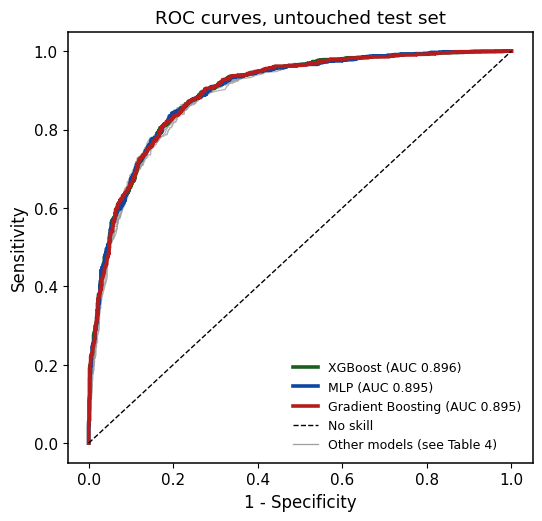

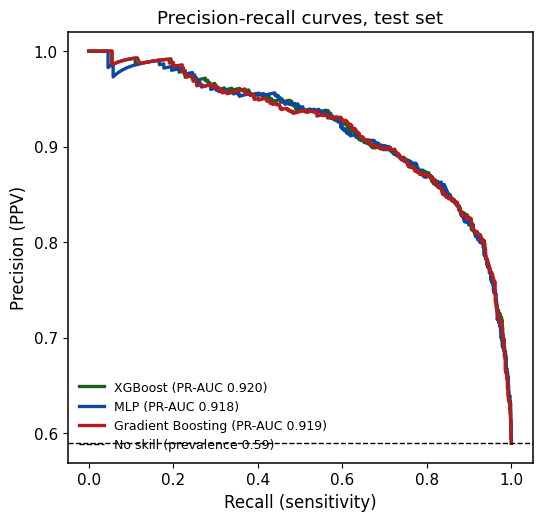

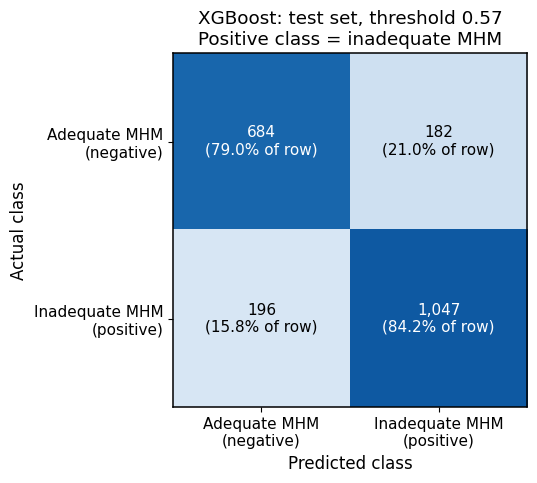

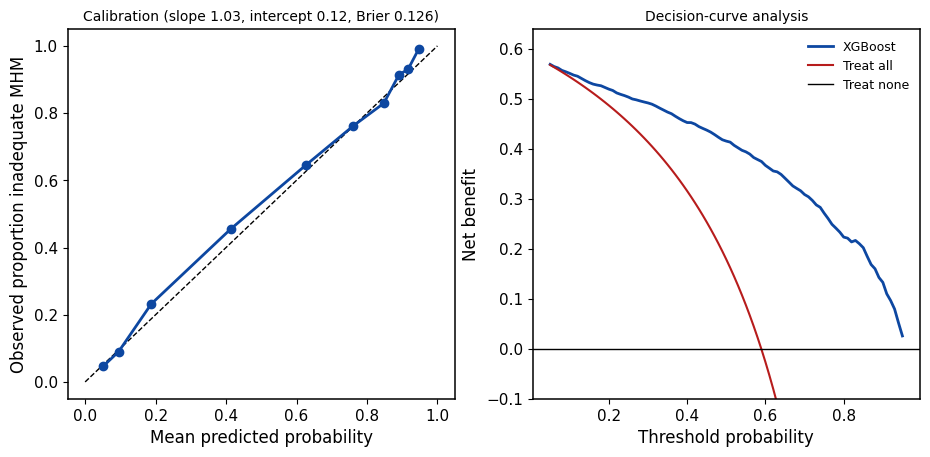

In [31]:
# --- 11. Publication-quality figures -------------------------------------------------
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.linewidth": 1.1, "axes.labelsize": 12, "legend.fontsize": 9,
                     "figure.dpi": 100, "savefig.dpi": 300, "pdf.fonttype": 42})
def save(fig, stem):
    fig.savefig(f"{OUT_DIR}/figures/{stem}.png", dpi=300, bbox_inches="tight"); fig.savefig(f"{OUT_DIR}/figures/{stem}.pdf", bbox_inches="tight"); plt.show()

top3 = order[:3]; pal = ["#1b5e20", "#0d47a1", "#b71c1c"]
# Fig 3 ROC
fig, ax = plt.subplots(figsize=(6, 5.6))
for n in order[3:]:
    f_, t_, _ = roc_curve(yte, RES[n]["p"]); ax.plot(f_, t_, color="#9e9e9e", lw=0.9, alpha=0.8)
for n, c in zip(top3, pal):
    f_, t_, _ = roc_curve(yte, RES[n]["p"]); ax.plot(f_, t_, color=c, lw=2.6, label=f"{n} (AUC {roc_auc_score(yte, RES[n]['p']):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="No skill"); ax.plot([], [], color="#9e9e9e", lw=0.9, label="Other models (see Table 4)")
ax.set_xlabel("1 - Specificity"); ax.set_ylabel("Sensitivity"); ax.legend(loc="lower right", frameon=False); ax.set_title("ROC curves, untouched test set")
save(fig, "Fig3_ROC_curves")
# Fig 4 PR
fig, ax = plt.subplots(figsize=(6, 5.6))
for n, c in zip(top3, pal):
    pr, rc, _ = precision_recall_curve(yte, RES[n]["p"]); ax.plot(rc, pr, color=c, lw=2.4, label=f"{n} (PR-AUC {average_precision_score(yte, RES[n]['p']):.3f})")
ax.axhline(yte.mean(), color="k", ls="--", lw=1, label=f"No skill (prevalence {yte.mean():.2f})")
ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision (PPV)"); ax.legend(loc="lower left", frameon=False); ax.set_title("Precision-recall curves, test set")
save(fig, "Fig4_PR_curves")
# Fig 5 confusion matrix (best model, primary threshold)
b = RES[BEST]; mb = full_metrics(yte, b["p"], b["thr_youden"]); cm = np.array([[mb["tn"], mb["fp"]], [mb["fn"], mb["tp"]]])
fig, ax = plt.subplots(figsize=(5.2, 4.6)); ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({100*cm[i, j]/cm[i].sum():.1f}% of row)", ha="center", va="center", fontsize=11, color="white" if cm[i, j] / cm[i].sum() > .5 else "black")
ax.set_xticks([0, 1], ["Adequate MHM\n(negative)", "Inadequate MHM\n(positive)"]); ax.set_yticks([0, 1], ["Adequate MHM\n(negative)", "Inadequate MHM\n(positive)"])
ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class"); ax.set_title(f"{BEST}: test set, threshold {b['thr_youden']:.2f}\nPositive class = inadequate MHM")
save(fig, "Fig5_confusion_matrix")
# Fig 6 calibration + decision curve
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
q = pd.qcut(b["p"], 10, duplicates="drop"); cal = pd.DataFrame({"p": b["p"], "y": yte, "q": q}).groupby("q").mean()
axs[0].plot([0, 1], [0, 1], "k--", lw=1); axs[0].plot(cal["p"], cal["y"], "o-", color="#0d47a1", lw=2)
axs[0].set_xlabel("Mean predicted probability"); axs[0].set_ylabel("Observed proportion inadequate MHM")
axs[0].set_title(f"Calibration (slope {mb['cal_slope']:.2f}, intercept {mb['cal_intercept']:.2f}, Brier {mb['brier']:.3f})", fontsize=10)
ths = np.linspace(0.05, 0.95, 91); n_ = len(yte); prev = yte.mean()
nb = [(((b["p"] >= t) & (yte == 1)).sum() - ((b["p"] >= t) & (yte == 0)).sum() * t / (1 - t)) / n_ for t in ths]
axs[1].plot(ths, nb, color="#0d47a1", lw=2, label=BEST); axs[1].plot(ths, [prev - (1 - prev) * t / (1 - t) for t in ths], color="#b71c1c", lw=1.5, label="Treat all"); axs[1].axhline(0, color="k", lw=1, label="Treat none")
axs[1].set_ylim(-0.1, prev + 0.05); axs[1].set_xlabel("Threshold probability"); axs[1].set_ylabel("Net benefit"); axs[1].legend(frameon=False); axs[1].set_title("Decision-curve analysis", fontsize=10)
save(fig, "Fig6_calibration_decision_curve")

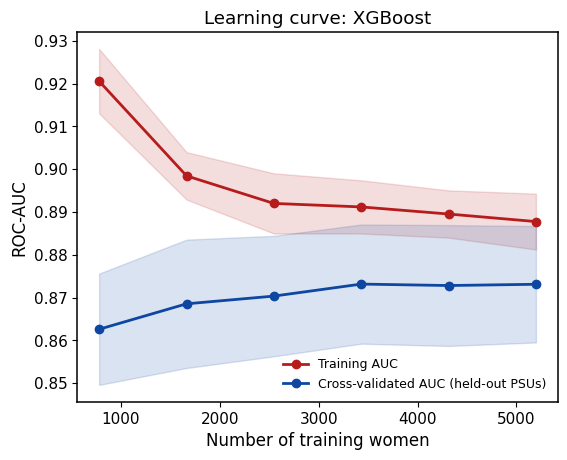

In [32]:
# --- 12. Learning curve (cluster-aware CV, validation on the ORIGINAL distribution, with bands) ----------
fracs = np.linspace(0.15, 1.0, 6)
lc_pipe = clone(RES[BEST]["pipe"])
sizes, trs, vas = learning_curve(lc_pipe, Xtr, ytr, cv=CV_SPLITS, train_sizes=fracs, scoring="roc_auc", n_jobs=1, random_state=SEED, shuffle=True)
fig, ax = plt.subplots(figsize=(6.2, 4.8))
for sc, c, lab in [(trs, "#b71c1c", "Training AUC"), (vas, "#0d47a1", "Cross-validated AUC (held-out PSUs)")]:
    ax.plot(sizes, sc.mean(1), "o-", color=c, lw=2, label=lab); ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=c, alpha=0.15)
ax.set_xlabel("Number of training women"); ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False, loc="lower right"); ax.set_title(f"Learning curve: {BEST}")
save(fig, "Fig7_learning_curve")
pd.DataFrame({"n_train": sizes, "train_auc_mean": trs.mean(1), "train_auc_sd": trs.std(1), "cv_auc_mean": vas.mean(1), "cv_auc_sd": vas.std(1)}).to_csv(f"{OUT_DIR}/tables/S5_learning_curve.csv", index=False)

In [33]:
# --- 13. Sensitivity analyses --------------------------------------------------------------------------
sens_rows = []
def add_sens(label, p_te, thr_note=""):
    sens_rows.append({"analysis": label, "ROC-AUC": round(roc_auc_score(yte, p_te), 4), "PR-AUC": round(average_precision_score(yte, p_te), 4), "note": thr_note})
add_sens(f"{BEST}: class weighting (primary)", RES[BEST]["p"])
# (a) imbalance strategy: none / SMOTEENN / random under-sampling (same tuned hyper-parameters, resampling in-fold only)
for strat, lab in [("none", "no resampling, no weights"), ("smoteenn", "SMOTEENN (training folds only)"), ("rus", "random under-sampling")]:
    try:
        est = clone(RES[BEST]["pipe"].named_steps["clf"].estimator)
        pp = make_pipe(est, strat, max_rows=SVM_MAX_ROWS if BEST == "SVM (RBF)" else None).fit(Xtr, ytr); add_sens(f"{BEST}: {lab}", pp.predict_proba(Xte)[:, 1])
    except Exception as e:
        print("skip", strat, e)
# (b) EDHS sampling weights used in fitting (weighted AUC reported alongside)
pw = make_pipe(clone(RES[BEST]["pipe"].named_steps["clf"].estimator), "none").fit(Xtr, ytr, clf__sample_weight=wtr)
pte_w = pw.predict_proba(Xte)[:, 1]
sens_rows.append({"analysis": f"{BEST}: survey-weighted fit, weighted test AUC", "ROC-AUC": round(roc_auc_score(yte, pte_w, sample_weight=wte), 4),
                  "PR-AUC": round(average_precision_score(yte, pte_w, sample_weight=wte), 4), "note": "DHS weight v005/1e6, normalised"})
sens_rows.append({"analysis": f"{BEST}: unweighted fit, weighted test AUC (comparison)", "ROC-AUC": round(roc_auc_score(yte, RES[BEST]["p"], sample_weight=wte), 4),
                  "PR-AUC": round(average_precision_score(yte, RES[BEST]["p"], sample_weight=wte), 4), "note": ""})
# (c) number of selected features / no selection
for k in [5, 10, 15, 20, len(FEATURES)]:
    pk = make_pipe(clone(RES[BEST]["pipe"].named_steps["clf"].estimator), "classweight", k=k).fit(Xtr, ytr); add_sens(f"{BEST}: top-{k} variables by mutual information", pk.predict_proba(Xte)[:, 1], "feature-count sensitivity")
sens = pd.DataFrame(sens_rows); sens.to_csv(f"{OUT_DIR}/tables/Table5_sensitivity_analyses.csv", index=False); print(sens.to_string(index=False))

                                               analysis  ROC-AUC  PR-AUC                            note
                     XGBoost: class weighting (primary)   0.8960  0.9196                                
                     XGBoost: no resampling, no weights   0.8960  0.9196                                
                XGBoost: SMOTEENN (training folds only)   0.8896  0.9085                                
                         XGBoost: random under-sampling   0.8961  0.9196                                
        XGBoost: survey-weighted fit, weighted test AUC   0.8831  0.9077 DHS weight v005/1e6, normalised
XGBoost: unweighted fit, weighted test AUC (comparison)   0.8831  0.9077                                
         XGBoost: top-5 variables by mutual information   0.8850  0.8998       feature-count sensitivity
        XGBoost: top-10 variables by mutual information   0.8895  0.9094       feature-count sensitivity
        XGBoost: top-15 variables by mutual information

In [34]:
# --- 14. Leakage audit and split-design comparison -----------------------------------------------------
birth = birth_level[["caseid"]].merge(analytic[["caseid", "inadequate_mhm", "v021"] + FEATURES], on="caseid", how="inner")   # one row per BIRTH (as in the first submission)
fixed_est = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=1, random_state=SEED, n_jobs=-1)
def quick_auc(Xa, ya, tr, te):
    pp = make_pipe(clone(fixed_est), "none").fit(Xa.iloc[tr], ya[tr]); return roc_auc_score(ya[te], pp.predict_proba(Xa.iloc[te])[:, 1])
audit_rows = []
# (a) birth-level rows + random 80/20 split  == first-submission design
Xb, yb = birth[FEATURES], birth["inadequate_mhm"].astype(int).values
tr_b, te_b = train_test_split(np.arange(len(birth)), test_size=0.2, stratify=yb, random_state=SEED)
shared = birth.iloc[te_b]["caseid"].isin(set(birth.iloc[tr_b]["caseid"])).mean()
audit_rows.append({"split design": "Birth-level rows, random 80/20 (first submission)", "n_rows": len(birth), "test_rows_whose_woman_is_in_training_%": round(100 * shared, 1), "ROC-AUC": round(quick_auc(Xb, yb, tr_b, te_b), 4)})
# (b) woman-level random split (ignores clustering)
tr_w, te_w = train_test_split(np.arange(len(analytic)), test_size=0.2, stratify=y, random_state=SEED)
shared_psu = analytic.iloc[te_w]["v021"].isin(set(analytic.iloc[tr_w]["v021"])).mean()
audit_rows.append({"split design": "Woman-level, random 80/20", "n_rows": len(analytic), "test_rows_whose_woman_is_in_training_%": 0.0, "test_women_whose_PSU_is_in_training_%": round(100 * shared_psu, 1), "ROC-AUC": round(quick_auc(X, y, tr_w, te_w), 4)})
# (c) woman-level, PSU-grouped (primary design)
audit_rows.append({"split design": "Woman-level, PSU-grouped 80/20 (primary)", "n_rows": len(analytic), "test_rows_whose_woman_is_in_training_%": 0.0, "test_women_whose_PSU_is_in_training_%": 0.0, "ROC-AUC": round(quick_auc(X, y, tr_idx, te_idx), 4)})
# (d) permuted-label check (5 permutations; should be close to 0.50 - values clearly above it deserve investigation)
perm_aucs = []
for _s in range(5):
    yperm = np.random.RandomState(SEED + _s).permutation(ytr); pp = make_pipe(ExtraTreesClassifier(n_estimators=150, random_state=SEED, n_jobs=-1), "none").fit(Xtr, yperm)
    perm_aucs.append(roc_auc_score(yte, pp.predict_proba(Xte)[:, 1]))
audit_rows.append({"split design": f"Permuted training labels, mean of 5 (SD {np.std(perm_aucs, ddof=1):.3f}); expected ~0.50", "n_rows": len(Xtr), "ROC-AUC": round(float(np.mean(perm_aucs)), 4)})
LEAK = pd.DataFrame(audit_rows); LEAK.to_csv(f"{OUT_DIR}/tables/Table6_leakage_audit_split_designs.csv", index=False); print(LEAK.to_string(index=False))

# single-feature screen (tautology check): AUC of each variable alone on the test set
sf = []
for f in FEATURES:
    if f in NUM + ORD + BIN:
        s = Xte[f].fillna(Xtr[f].median()); a = roc_auc_score(yte, s)
    else:
        mp = pd.Series(ytr, index=Xtr.index).groupby(Xtr[f]).mean(); s = Xte[f].map(mp).fillna(ytr.mean()); a = roc_auc_score(yte, s)
    sf.append({"feature": f, "single_feature_AUC": round(max(a, 1 - a), 4)})
SF = pd.DataFrame(sf).sort_values("single_feature_AUC", ascending=False); SF.to_csv(f"{OUT_DIR}/tables/S6_single_feature_AUC_tautology_screen.csv", index=False)
print("Highest single-feature AUCs (a value near 1 would signal a feature that restates the outcome):"); print(SF.head(8).to_string(index=False))
dup = Xte.merge(Xtr.drop_duplicates(), how="inner", on=FEATURES).shape[0]
print(f"Test women whose full predictor vector is identical to a training woman: {dup} ({100*dup/len(Xte):.1f}%)")

# redundancy among predictors (wealth proxies etc.)
sel_final = RES[BEST]["pipe"].named_steps["prep"].keep_vars_
quant = [f for f in sel_final if f in NUM + ORD + BIN]
corr = analytic[quant].corr(method="spearman"); pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(quant) for b in quant[i + 1:] if abs(corr.loc[a, b]) >= 0.7]
pd.DataFrame(pairs, columns=["feature_1", "feature_2", "spearman_rho"]).to_csv(f"{OUT_DIR}/tables/S7_redundant_predictor_pairs.csv", index=False)
print("Highly correlated selected predictors (|rho| >= 0.7):", pairs)

                                                  split design  n_rows  test_rows_whose_woman_is_in_training_%  ROC-AUC  test_women_whose_PSU_is_in_training_%
             Birth-level rows, random 80/20 (first submission)   37471                                    92.2   0.9927                                    NaN
                                     Woman-level, random 80/20    9915                                     0.0   0.8269                                  100.0
                      Woman-level, PSU-grouped 80/20 (primary)    9915                                     0.0   0.8612                                    0.0
Permuted training labels, mean of 5 (SD 0.024); expected ~0.50    7806                                     NaN   0.4810                                    NaN
Highest single-feature AUCs (a value near 1 would signal a feature that restates the outcome):
                         feature  single_feature_AUC
           Wealth index combined              0.8446
    

In [35]:
# --- 15. Mutual-information results for ALL candidate variables + binning sensitivity ---------------------------
prep_final = RES[BEST]["pipe"].named_steps["prep"]
S2 = prep_final.mi_scores_.rename("mutual_information").reset_index().rename(columns={"index": "feature"})
S2["rank"] = np.arange(1, len(S2) + 1); S2["selected_top_k"] = S2["rank"] <= K_FEATURES; S2 = S2.merge(vdict[["feature", "dhs_variable", "label"]], on="feature", how="left")
bins_rank = {}
for nb_ in [5, 10, 20]:
    Xd = Xtr.copy()
    for c in NUM: Xd[c] = pd.qcut(Xd[c].rank(method="first"), nb_, labels=False)
    Xd = Xd.apply(lambda s: s.fillna(s.mode().iloc[0])); codes = Xd.apply(lambda s: pd.factorize(s)[0])
    mi_ = pd.Series(mutual_info_classif(codes, ytr, discrete_features=True, random_state=SEED), index=FEATURES).sort_values(ascending=False); bins_rank[nb_] = list(mi_.index[:K_FEATURES])
    S2[f"top{K_FEATURES}_if_{nb_}_quantile_bins"] = S2["feature"].isin(bins_rank[nb_])
S2.to_csv(f"{OUT_DIR}/tables/S2_mutual_information_all_variables.csv", index=False); print(S2[["rank", "feature", "mutual_information", "selected_top_k"]].head(20).to_string(index=False))

 rank                                        feature  mutual_information  selected_top_k
    1                          Wealth index combined            0.176408            True
    2                      Education in single years            0.165881            True
    3                      Highest educational level            0.148298            True
    4               Frequency of watching television            0.127723            True
    5                     Type of place of residence            0.123087            True
    6                      Household has: television            0.120169            True
    7                                       Literacy            0.108510            True
    8                    Time to get to water source            0.095266            True
    9                           Type of cooking fuel            0.081939            True
   10                    Household has: refrigerator            0.074055            True
   11                

In [40]:
# --- 15. Mutual-information results for ALL candidate variables + binning sensitivity ---------------------------
prep_final = RES[BEST]["pipe"].named_steps["prep"]

# To get MI scores for ALL raw features (not just top-k selected ones),
# we use the underlying preprocessor's transformer or evaluate on all features:
Xt = prep_final.pre_.transform(Xtr)
names = list(prep_final.pre_.get_feature_names_out())
disc = np.array([source_var(n) not in NUM for n in names])
mi_full = mutual_info_classif(Xt, ytr, discrete_features=disc, random_state=SEED)
srcs = [source_var(n) for n in names]
all_mi_scores = pd.Series(mi_full, index=srcs).groupby(level=0).max().sort_values(ascending=False)

S2 = all_mi_scores.rename("mutual_information").reset_index().rename(columns={"index": "feature"})
S2["rank"] = np.arange(1, len(S2) + 1)
S2["selected_top_k"] = S2["rank"] <= len(S2)  # All candidate features included
S2 = S2.merge(vdict[["feature", "dhs_variable", "label"]], on="feature", how="left")

bins_rank = {}
for nb_ in [5, 10, 20]:
    Xd = Xtr.copy()
    for c in NUM:
        if c in Xd.columns:
            Xd[c] = pd.qcut(Xd[c].rank(method="first"), nb_, labels=False, duplicates="drop")
    Xd = Xd.apply(lambda s: s.fillna(s.mode().iloc[0]) if not s.mode().empty else s)
    codes = Xd.apply(lambda s: pd.factorize(s)[0])

    # Compute MI for all features in FEATURES
    mi_ = pd.Series(
        mutual_info_classif(codes[FEATURES], ytr, discrete_features=True, random_state=SEED),
        index=FEATURES
    ).sort_values(ascending=False)

    bins_rank[nb_] = list(mi_.index)
    S2[f"in_top_{nb_}_quantile_bins"] = S2["feature"].isin(bins_rank[nb_])

S2.to_csv(f"{OUT_DIR}/tables/S2_mutual_information_all_variables.csv", index=False)
print(S2[["rank", "feature", "mutual_information"]].to_string(index=False))

 rank                                        feature  mutual_information
    1                          Wealth index combined            0.176408
    2                      Education in single years            0.165881
    3                      Highest educational level            0.148298
    4               Frequency of watching television            0.127723
    5                     Type of place of residence            0.123087
    6                      Household has: television            0.120169
    7                                       Literacy            0.108510
    8                    Time to get to water source            0.095266
    9                           Type of cooking fuel            0.081939
   10                    Household has: refrigerator            0.074055
   11                     Household has: electricity            0.072080
   12                       Total children ever born            0.071913
   13            Living children + current pregnanc

In [36]:
# --- 16. Baselines: survey-weighted logistic regression (cluster-robust) -----------------------------------------
if sm is not None:
    pre_all = PreprocSelect(k=len(FEATURES), seed=SEED, use_mi=False).fit(Xtr, ytr)
    Ztr = pd.DataFrame(pre_all.transform(Xtr), columns=pre_all.get_feature_names_out()); Zte = pd.DataFrame(pre_all.transform(Xte), columns=pre_all.get_feature_names_out())
    drop = []
    for f in NOM:
        cols_f = sorted([n for n in Ztr.columns if source_var(n) == f])
        if cols_f: drop.append(cols_f[0])      # reference category
    Ztr, Zte = Ztr.drop(columns=drop), Zte.drop(columns=drop)
    glm = sm.GLM(ytr, sm.add_constant(Ztr), family=sm.families.Binomial(), freq_weights=wtr).fit(cov_type="cluster", cov_kwds={"groups": gtr})
    p_glm = glm.predict(sm.add_constant(Zte, has_constant="add"))
    orr = pd.DataFrame({"OR": np.exp(glm.params), "ci_low": np.exp(glm.conf_int()[0]), "ci_high": np.exp(glm.conf_int()[1]), "p": glm.pvalues}).round(4)
    orr.to_csv(f"{OUT_DIR}/tables/S8_survey_weighted_logistic_regression_ORs.csv");
    print(f"Survey-weighted logistic regression (all 33 variables, cluster-robust SE): test ROC-AUC {roc_auc_score(yte, p_glm):.4f}, weighted AUC {roc_auc_score(yte, p_glm, sample_weight=wte):.4f}")
else:
    print("statsmodels not installed: skipping survey-weighted logistic regression")

Survey-weighted logistic regression (all 33 variables, cluster-robust SE): test ROC-AUC 0.8908, weighted AUC 0.8715


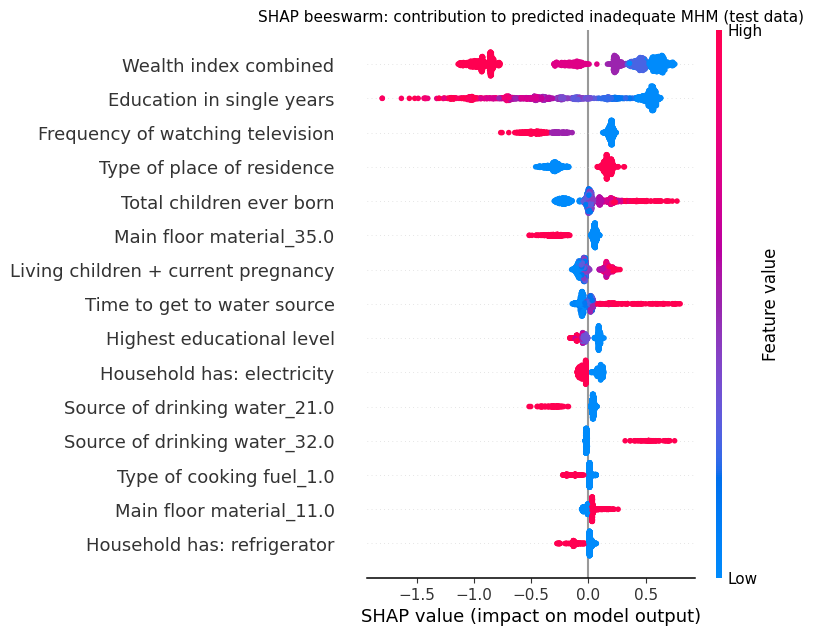

 rank                           predictor  mean_abs_SHAP  bootstrap_95CI dhs_variable
    1               Wealth index combined        0.57637 0.56204-0.58902         v190
    2           Education in single years        0.53313 0.52367-0.54750         v133
    3    Frequency of watching television        0.27437 0.26816-0.28144         v159
    4          Type of place of residence        0.21900 0.21555-0.22306         v025
    5                 Main floor material        0.13128 0.12597-0.13777         v127
    6            Total children ever born        0.12573 0.11961-0.13198         v201
    7            Source of drinking water        0.09945 0.09240-0.10851         v113
    8 Living children + current pregnancy        0.08972 0.08732-0.09262         v219
    9         Time to get to water source        0.07570 0.07050-0.08167         v115
   10           Highest educational level        0.07150 0.06985-0.07275         v106
   11          Household has: electricity        0.068

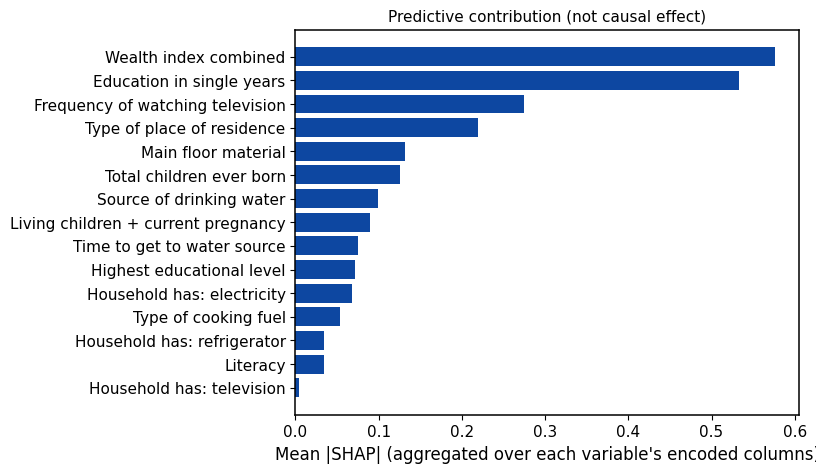

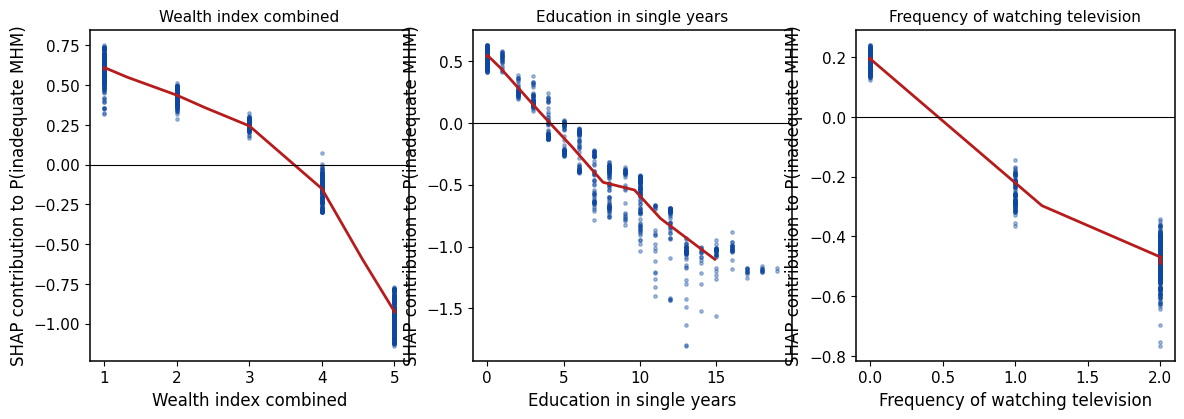

In [37]:
# --- 17. SHAP: explains the model's predictions of INADEQUATE MHM (class 1) on the TEST data -----------------------
if shap is not None:
    mdl = RES[BEST]["pipe"].named_steps["clf"].estimator_; prep_b = RES[BEST]["pipe"].named_steps["prep"]
    rs = np.random.RandomState(SEED); sub = rs.choice(len(Xte), min(1500, len(Xte)), replace=False)
    Zs = pd.DataFrame(prep_b.transform(Xte.iloc[sub]), columns=prep_b.get_feature_names_out()); Xraw = Xte.iloc[sub].reset_index(drop=True)
    tree_like = isinstance(mdl, (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, DecisionTreeClassifier)) or "XGB" in type(mdl).__name__ or "LGBM" in type(mdl).__name__
    if tree_like:
        expl = shap.TreeExplainer(mdl); sv = expl.shap_values(Zs, check_additivity=False)
    else:
        bg = shap.sample(pd.DataFrame(prep_b.transform(Xtr), columns=prep_b.get_feature_names_out()), 100, random_state=SEED)
        expl = shap.KernelExplainer(lambda a: mdl.predict_proba(a)[:, 1], bg); sv = expl.shap_values(Zs.iloc[:300]); Zs = Zs.iloc[:300]; Xraw = Xraw.iloc[:300]
    sv = np.array(sv[1]) if isinstance(sv, list) else np.array(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]
    sv_df = pd.DataFrame(sv, columns=Zs.columns)
    plt.figure(); shap.summary_plot(sv, Zs, show=False, max_display=15); fig = plt.gcf(); fig.set_size_inches(8, 6.2); plt.title("SHAP beeswarm: contribution to predicted inadequate MHM (test data)", fontsize=11); save(fig, "Fig8_SHAP_beeswarm")
    agg = pd.DataFrame({v: sv_df[[c for c in sv_df.columns if source_var(c) == v]].sum(axis=1) for v in sorted({source_var(c) for c in sv_df.columns})})
    imp = agg.abs().mean().sort_values(ascending=False)
    T_shap = pd.DataFrame({"rank": range(1, len(imp) + 1), "predictor": imp.index, "mean_abs_SHAP": imp.values.round(5),
                           "bootstrap_95CI": [f"{np.percentile([agg[v].abs().iloc[rs.randint(0, len(agg), len(agg))].mean() for _ in range(200)], 2.5):.5f}-"
                                              f"{np.percentile([agg[v].abs().iloc[rs.randint(0, len(agg), len(agg))].mean() for _ in range(200)], 97.5):.5f}" for v in imp.index]})
    T_shap = T_shap.merge(vdict[["feature", "dhs_variable"]], left_on="predictor", right_on="feature", how="left").drop(columns="feature"); T_shap.to_csv(f"{OUT_DIR}/tables/Table7_SHAP_importance.csv", index=False); print(T_shap.head(15).to_string(index=False))
    fig, ax = plt.subplots(figsize=(6.5, 5)); top = imp.head(15)[::-1]; ax.barh(top.index, top.values, color="#0d47a1"); ax.set_xlabel("Mean |SHAP| (aggregated over each variable's encoded columns)"); ax.set_title("Predictive contribution (not causal effect)", fontsize=11); save(fig, "Fig8b_SHAP_bar")
    fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
    for ax, v in zip(axs, list(imp.index[:3])):
        if v in NUM + ORD + BIN:
            xv = Xraw[v].values; ax.scatter(xv, agg[v], s=6, alpha=0.35, color="#0d47a1")
            try:
                bins_ = pd.qcut(pd.Series(xv).rank(method="first"), 12, labels=False); ax.plot(pd.Series(xv).groupby(bins_).mean(), agg[v].groupby(bins_).mean(), color="#b71c1c", lw=2)
            except Exception: pass
            ax.set_xlabel(vdict.set_index("feature").loc[v, "label"])
        else:
            cats = pd.Series(Xraw[v].values).map(LABELS.get(v, {})).fillna(pd.Series(Xraw[v].values).astype(str)); order_c = agg[v].groupby(cats.values).mean().sort_values().index
            ax.boxplot([agg[v].values[cats.values == c] for c in order_c], labels=[str(c)[:14] for c in order_c], showfliers=False); ax.tick_params(axis="x", rotation=70)
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("SHAP contribution to P(inadequate MHM)"); ax.set_title(v, fontsize=11)
    save(fig, "Fig9_SHAP_dependence_top3")
else:
    print("shap not installed")

In [41]:
# --- Supplementary Table S7: Correlation matrix using all features ---
# Compute Spearman rank correlation matrix across all numeric/ordinal features in Xtr
corr_matrix = Xtr.corr(method="spearman")

# Save Supplementary Table S7 to CSV
corr_matrix.to_csv(f"{OUT_DIR}/tables/S7_all_features_correlation.csv")

# Print matrix summary
print("Supplementary Table S7: Full Correlation Matrix (All Features)")
print(corr_matrix.to_string())

Supplementary Table S7: Full Correlation Matrix (All Features)
                                                Respondent's current age  Age in 5-year groups  Highest educational level  Education in single years  Literacy  Religion  Current marital status  Wealth index combined  Type of place of residence    Region  Frequency of reading newspaper or magazine  Frequency of listening to radio  Frequency of watching television  Source of drinking water  Time to get to water source  Type of toilet facility  Toilet facilities shared with other households  Type of cooking fuel  Household has: electricity  Household has: radio  Household has: television  Household has: refrigerator  Household has: bicycle  Household has: motorcycle/scooter  Household has: car/truck  Main floor material  Main wall material  Main roof material  Total children ever born  Number of living children  Living children + current pregnancy  Currently pregnant  Ever had a terminated pregnancy
Respondent's current age   